# Bedroom Humidity EDA


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

In [1]:
# data analysis
import datetime
import numpy as np
import pandas as pd

# preprocessing
from utils import DataCleanPipleLine
from sklearn.preprocessing import StandardScaler

# viz
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from utils import plotting as plot

# OS
import os
from dotenv import load_dotenv

load_dotenv()

# set theme for the book
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

title_params = {
    'fontsize' : 20,
    'fontweight' : 'bold',
    'color':'grey'
}

## Data Import

In [2]:
# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = cleaning_pipeline.RunPipeline()


****************************************************************************************************
DF Shape: (252486, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
252485  2026-11-13 11:58:03             13.80  1001.73920  63.200196
252486  2026-11-13 11:59:03             13.83  1001.73920  62.694336
252487  2026-11-13 12:00:03             13.84  1001.75440  62.717772
252488  2026-11-13 12:01:03             13.84  1001.74670  62.362304
252489  2026-11-13 12:02:03             13.83  1001.78468  62.449220
252490  2026-11-13 12:03:04             13.86  1001.73160  62.432616
252491  2026-11-13 12:04:04             13.84  1001.74670  62.406250
252492  2026-11-13 12:05:04             13.87  1001.68590  61.945312
252493  2026-11-13 12:06:04             13.86  1001.67

c:\Users\Charl\OneDrive\Python\Projects\Temp Data\bedroom-humidity-forecasting\utils\DataCleanPipleLine.py:136: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  self.df['YearMonth'] = self.df['DateTime'].dt.to_period("M")


In [3]:
window_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 252471 entries, 2026-03-29 20:54:00+00:00 to 2026-11-13 12:07:00+00:00
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     252471 non-null  float64            
 1   Pressure             252471 non-null  float64            
 2   Humidity             252471 non-null  float64            
 3   DateTime             252470 non-null  datetime64[us, UTC]
 4   Date                 252470 non-null  datetime64[s]      
 5   UkDate               252470 non-null  str                
 6   YearMonth            252470 non-null  period[M]          
 7   EndOfWeek            252470 non-null  datetime64[us, UTC]
 8   Time                 252470 non-null  object             
 9   Time_Numeric         252470 non-null  timedelta64[us]    
 10  DailyAvgTemperature  252470 non-null  float64            
 11  DailyAvgHumidity     252470 no

In [4]:
# import data
file_location2 = os.getenv("F_LOC2")

# run data load
aq_cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location2)

# run pipeline
door_df = aq_cleaning_pipeline.RunPipeline()

****************************************************************************************************
DF Shape: (243317, 6)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity  eCo2  \
243316  2026-11-13 11:57:44             17.30  1003.15452  54.359376   860   
243317  2026-11-13 11:58:44             17.31  1003.20624  54.091796   863   
243318  2026-11-13 11:59:44             17.26  1003.28032  54.366210   857   
243319  2026-11-13 12:00:44             17.28  1003.26120  54.166992   837   
243320  2026-11-13 12:01:44             17.24  1003.24660  53.881836   850   
243321  2026-11-13 12:02:44             17.24  1003.24660  54.038084   833   
243322  2026-11-13 12:03:44             17.23  1003.17690  54.171876   833   
243323  2026-11-13 12:04:44             17.28  1003

c:\Users\Charl\OneDrive\Python\Projects\Temp Data\bedroom-humidity-forecasting\utils\DataCleanPipleLine.py:136: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  self.df['YearMonth'] = self.df['DateTime'].dt.to_period("M")


In [5]:
door_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 243297 entries, 2026-04-05 18:15:00+00:00 to 2026-11-13 12:06:00+00:00
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     243297 non-null  float64            
 1   Pressure             243297 non-null  float64            
 2   Humidity             243297 non-null  float64            
 3   eCo2                 243297 non-null  float64            
 4   VOC                  243297 non-null  float64            
 5   DateTime             243296 non-null  datetime64[us, UTC]
 6   Date                 243296 non-null  datetime64[s]      
 7   UkDate               243296 non-null  str                
 8   YearMonth            243296 non-null  period[M]          
 9   EndOfWeek            243296 non-null  datetime64[us, UTC]
 10  Time                 243296 non-null  object             
 11  Time_Numeric         243296 no

## Data Inespection

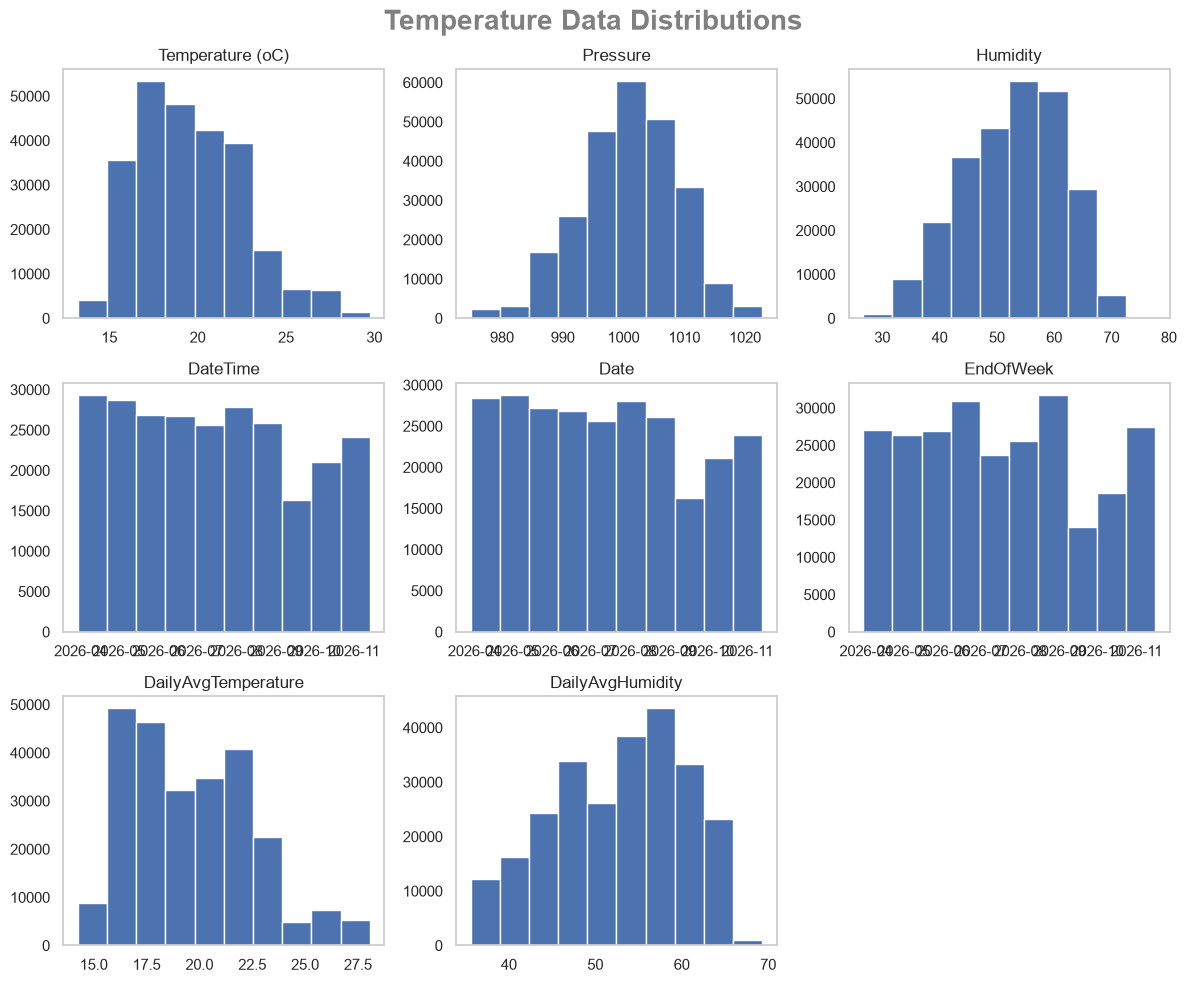

In [6]:
# show distributions
window_df.hist(
    grid=False, 
    figsize=(12, 10)
    );

plt.suptitle(
    "Temperature Data Distributions",
    fontsize=20,
    fontweight="bold",
    color="grey"
)

plt.tight_layout()

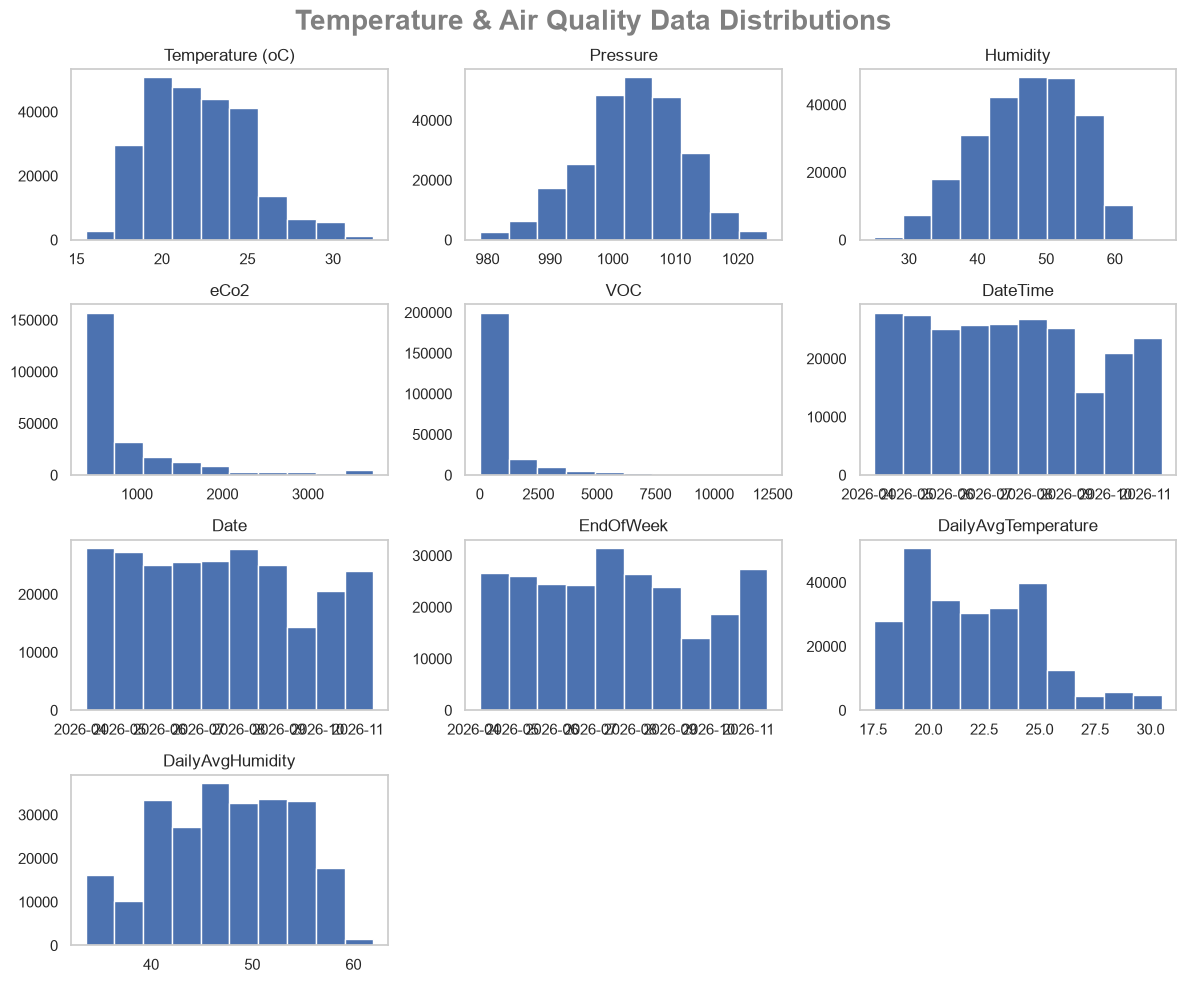

In [7]:
door_df.hist(
    grid=False, 
    figsize=(12, 10)
    );

plt.suptitle(
    "Temperature & Air Quality Data Distributions",
    fontsize=20,
    fontweight="bold",
    color="grey"
)
plt.tight_layout()

## EDA

1. Review how the data trends over time
2. Compute the difference between the two sensors - Does it get worse over times or specific periods?
3. When is humidity at its worse? (time during the day and month of the year)
4. Can we determine when humidity levels worsen? (ie the rate of change over time for when humidity levels increase)

#### Temperature Time Series

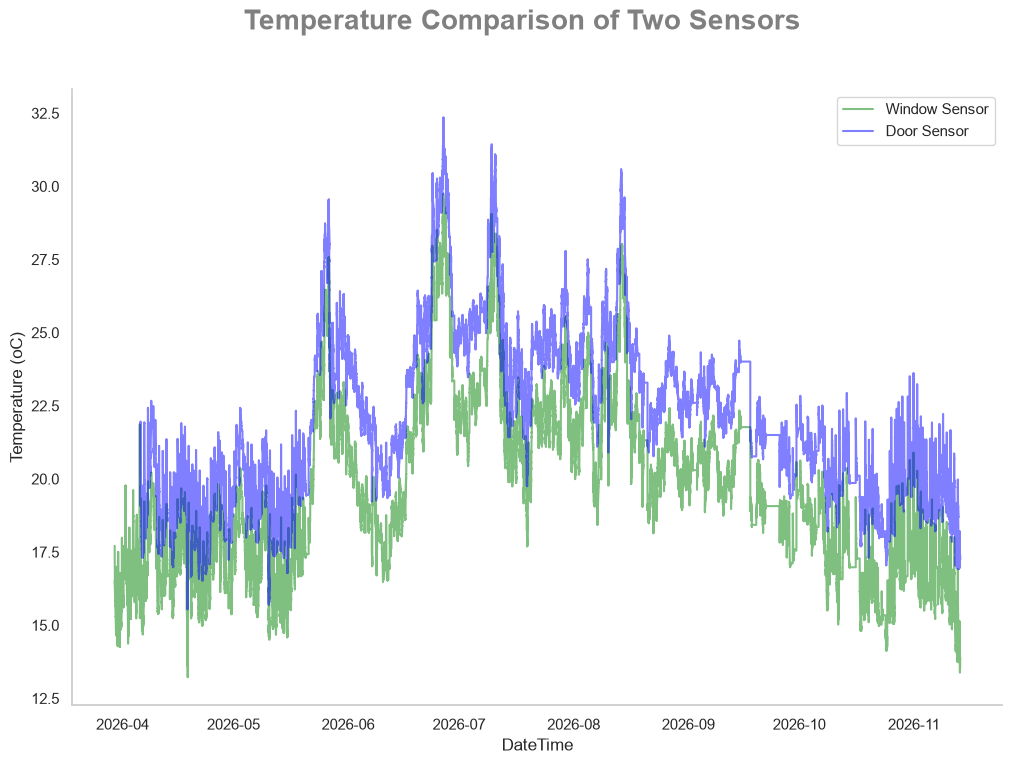

In [8]:
# review time series data trend over time

plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["Temperature (oC)"], 
    title="Temperature Comparison of Two Sensors",
    saved_name="Temperature Comparison of Two Sensors"
    )


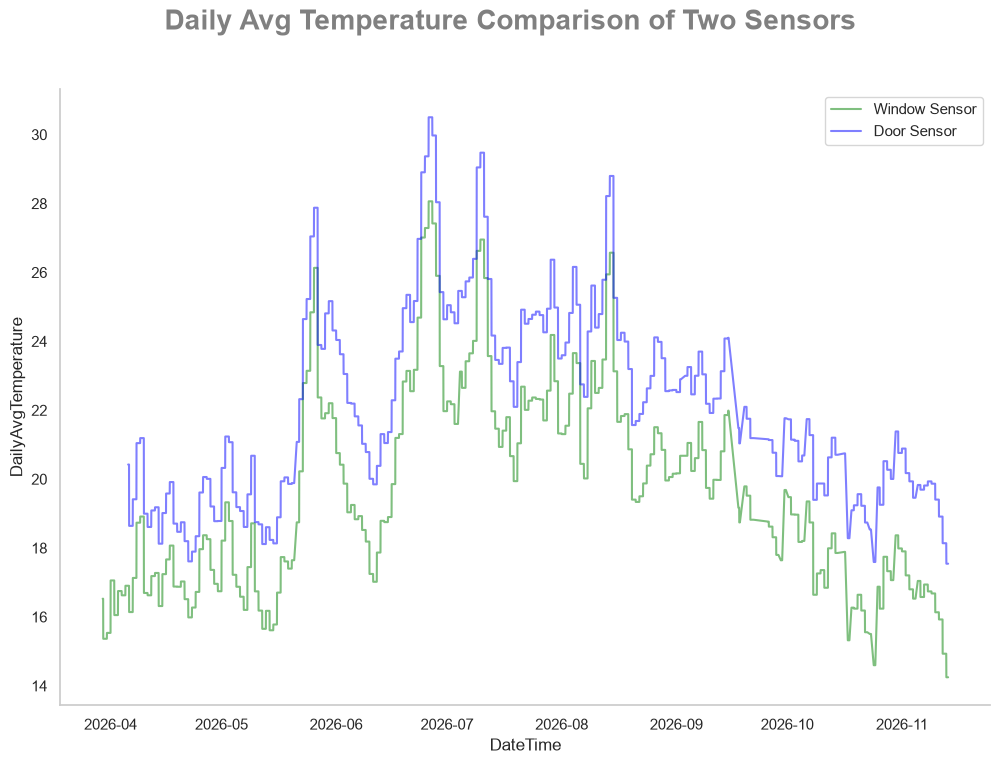

In [9]:
# show daily average time series plot
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["DailyAvgTemperature"], 
    title="Daily Avg Temperature Comparison of Two Sensors",
    saved_name="Daily Avg Temperature Comparison of Two Sensors"
    )


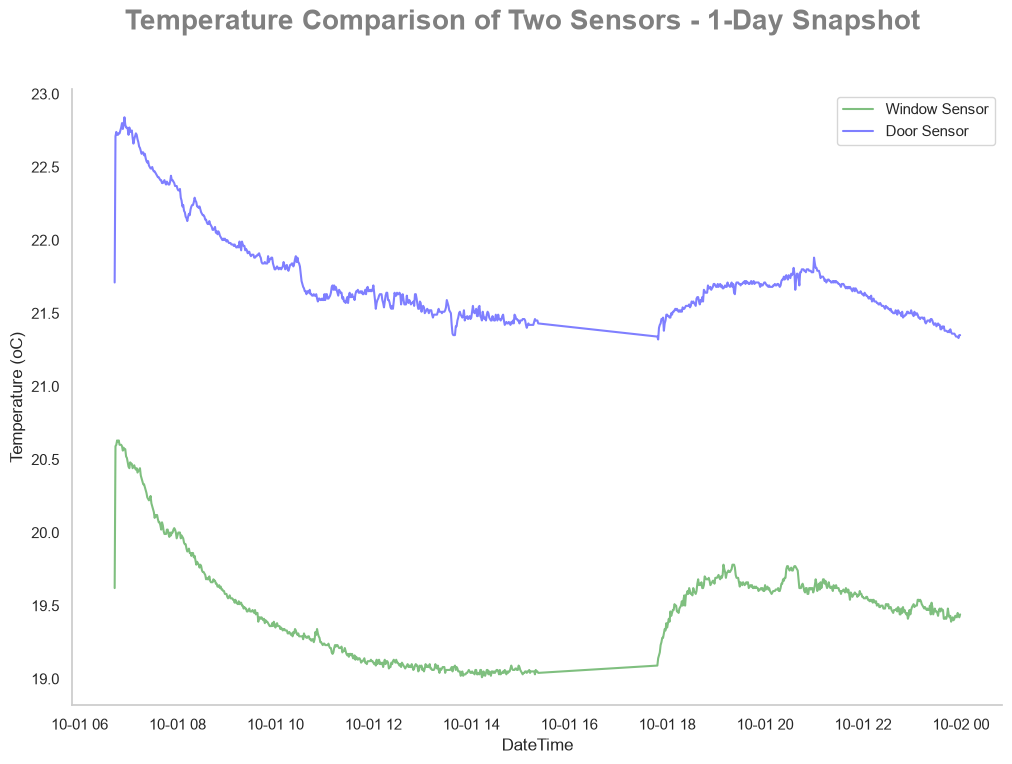

In [10]:
# plot a full day in line plot
oct_26 = pd.to_datetime("2026-10-01")
win_full_day_oct = window_df[window_df["DateTime"].dt.date == oct_26.date()]
door_full_day_oct = door_df[door_df["DateTime"].dt.date == oct_26.date()]

plot.plot_time_series(
    dfs=[win_full_day_oct, door_full_day_oct], 
    x_col="DateTime", 
    y_col=["Temperature (oC)"], 
    title="Temperature Comparison of Two Sensors - 1-Day Snapshot",
    saved_name="Temperature Comparison of Two Sensors - 1-Day Snapshot Oct 2026"
    )


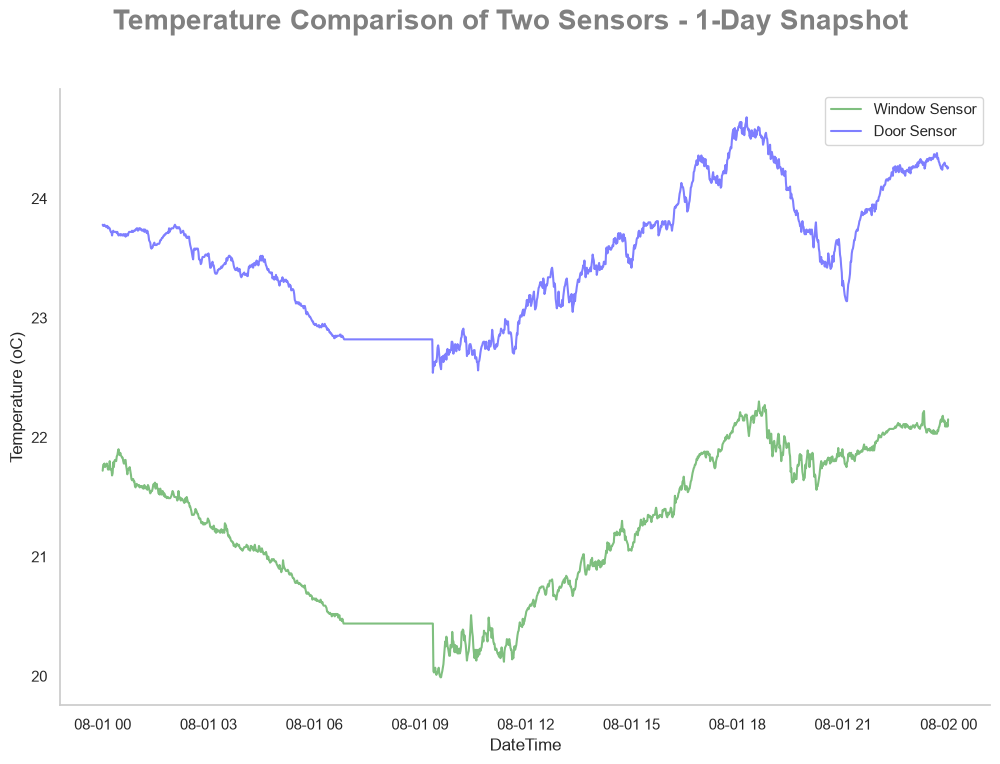

In [11]:
# choose a day in a warmer month to see if the sensors are more aligned

# plot a full day in line plot
aug_26 = pd.to_datetime("2026-08-01")
win_full_day_aug = window_df[window_df["DateTime"].dt.date == aug_26.date()]
door_full_day_aug = door_df[door_df["DateTime"].dt.date == aug_26.date()]

plot.plot_time_series(
    dfs=[win_full_day_aug, door_full_day_aug], 
    x_col="DateTime", 
    y_col=["Temperature (oC)"], 
    title="Temperature Comparison of Two Sensors - 1-Day Snapshot",
    saved_name="Temperature Comparison of Two Sensors - 1-Day Snapshot August 2026"
    )

##### **Notes**

1. There is evidence of cyclic behaviour -> The influence of time of the year and time of the day
2. The latest data shows that we are returing to temperatures of Apr 2026.
3. Door sensors appears to be consistently warmer in comparison to Window sesnor, even though the window sesnor is closer to a radiator than the other sensor, suggesting colder air is breaching the room through either the window or wall or both.


#### Humidity Time Series

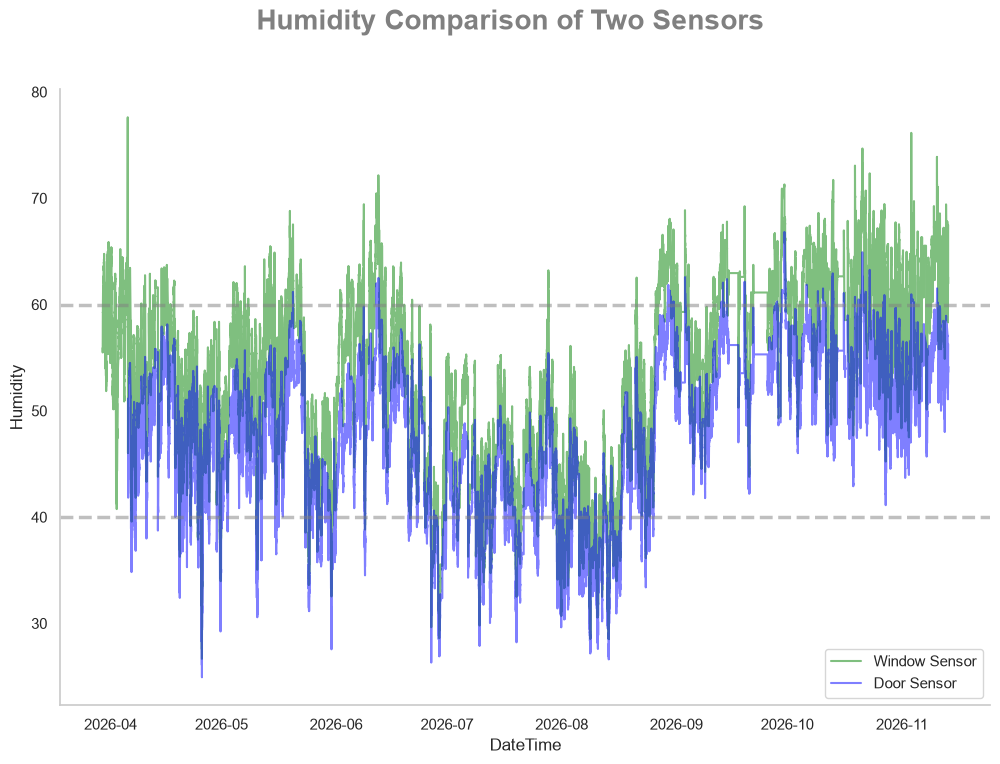

In [12]:
# now humidity
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Humidity Comparison of Two Sensors",
    saved_name="Humidity Comparison of Two Sensors",
    add_hlines=True
    )

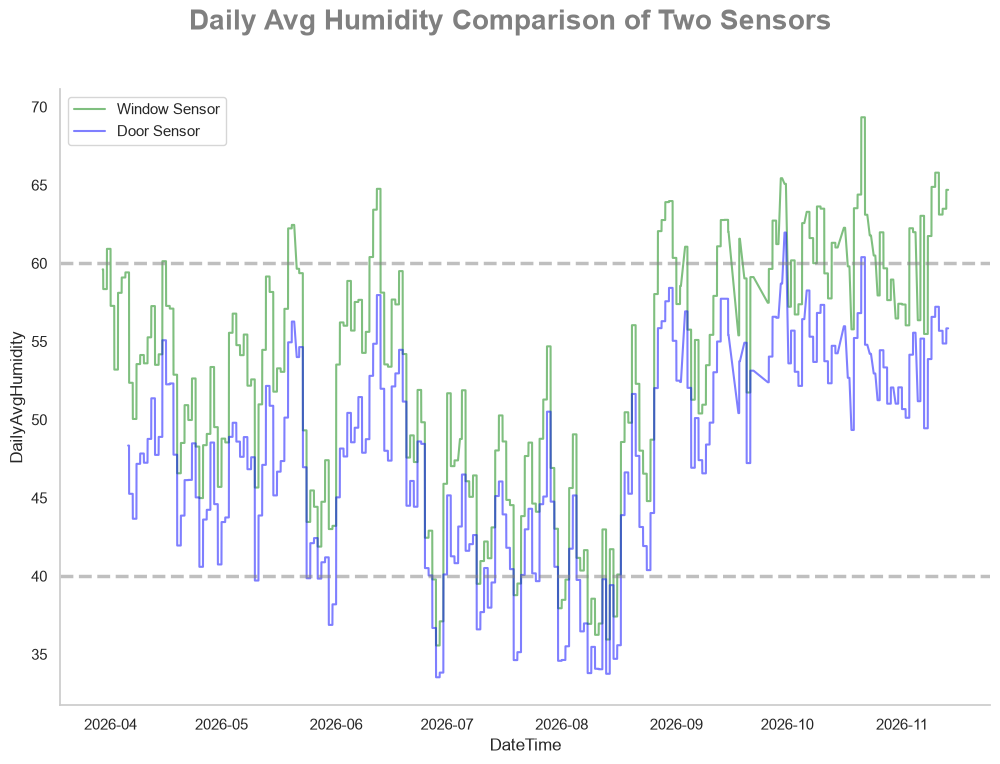

In [13]:
# Take the daily average and plot for ease of analysis
# show daily average time series plot
# according to Dreams, the range in which the humidity should be is in the range 40% and 60% for optimal comfort and health. 
# This plot will help visualize how the humidity levels from both sensors compare to this recommended range.
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["DailyAvgHumidity"], 
    title="Daily Avg Humidity Comparison of Two Sensors",
    saved_name="Daily Avg Humidity Comparison of Two Sensors",
    add_hlines=True
    )




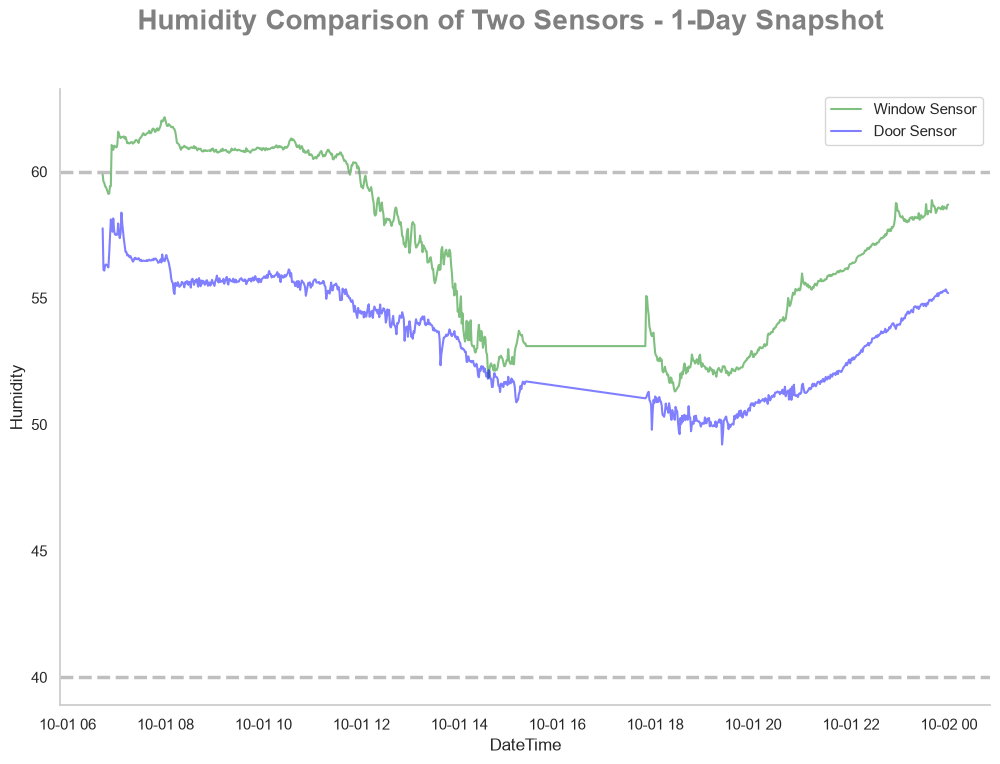

In [14]:
# choose a day in a warmer month to see if the sensors are more aligned

plot.plot_time_series(
    dfs=[win_full_day_oct, door_full_day_oct], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Humidity Comparison of Two Sensors - 1-Day Snapshot",
    saved_name="Humidity Comparison of Two Sensors - 1-Day Snapshot October 2026",
    add_hlines=True
    )

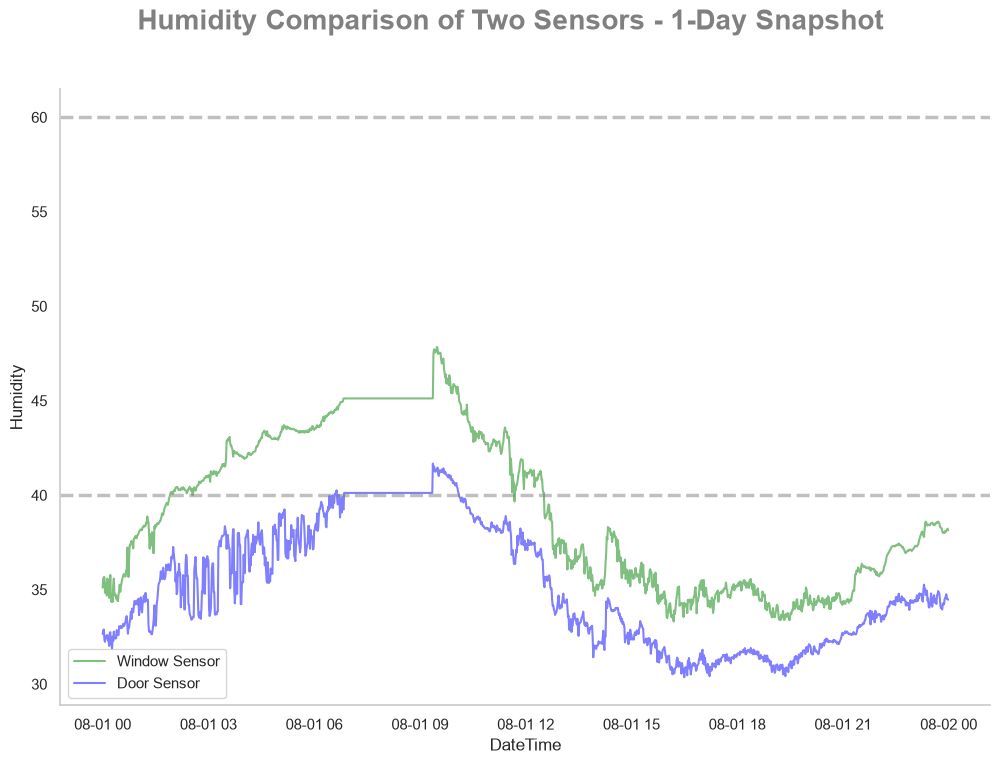

In [15]:
plot.plot_time_series(
    dfs=[win_full_day_aug, door_full_day_aug], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Humidity Comparison of Two Sensors - 1-Day Snapshot",
    saved_name="Humidity Comparison of Two Sensors - 1-Day Snapshot August 2026",
    add_hlines=True
    )

##### **Notes**

1. Summer months appear to be less humid than colder months.
2. Humidity levels typically lie above the max line (60%) for one of the sensors while the other appears to sit comformatably below the max line.
3. The colder months appear to show dift as humidity levels rise for both sensors.

#### Temperature Sensor Drift

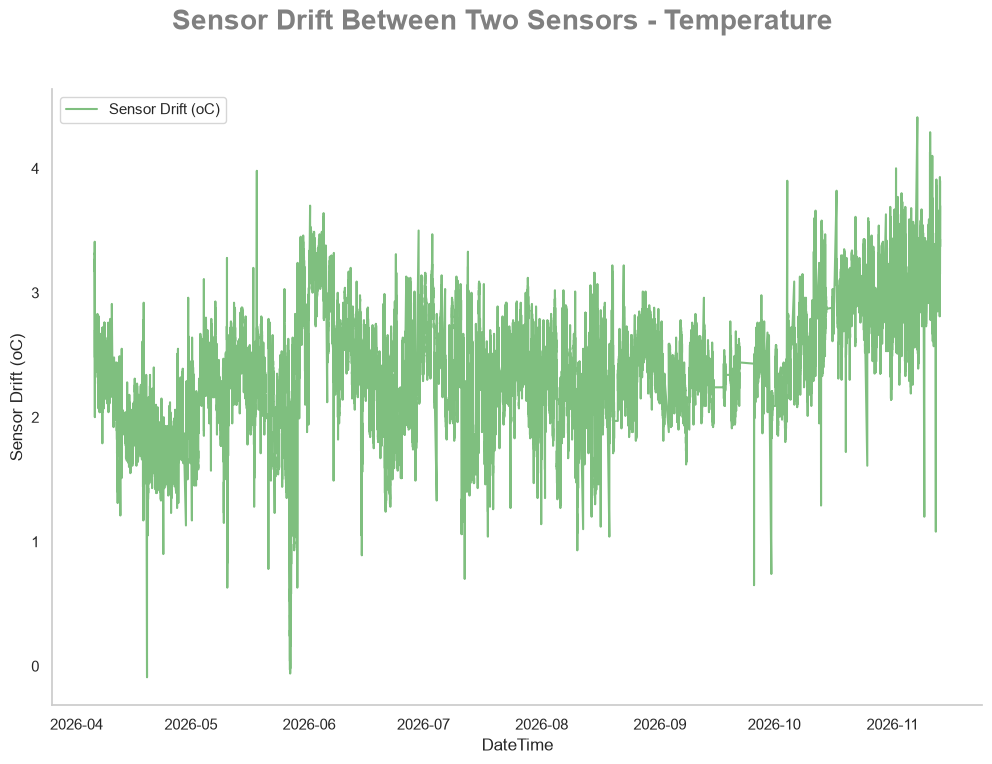

In [16]:
# How much of a difference is there between the two sensors?

tmp_sensor_drift = pd.DataFrame((door_df['Temperature (oC)'] - window_df['Temperature (oC)']).dropna())

tmp_sensor_drift.rename(columns={'Temperature (oC)': 'Sensor Drift (oC)'}, inplace=True)

plot.plot_time_series(
    dfs=[tmp_sensor_drift], 
    x_col="DateTime", 
    y_col=["Sensor Drift (oC)"], 
    title="Sensor Drift Between Two Sensors - Temperature",
    saved_name="Sensor Drift Between Two Sensors"
    )

count    241933.00000
mean          2.39145
std           0.45573
min          -0.09000
25%           2.11000
50%           2.40000
75%           2.68000
max           4.41000
Name: Sensor Drift (oC), dtype: float64 

Skewness: -0.14167509161975925
Kurtosis: 0.34139069933464405


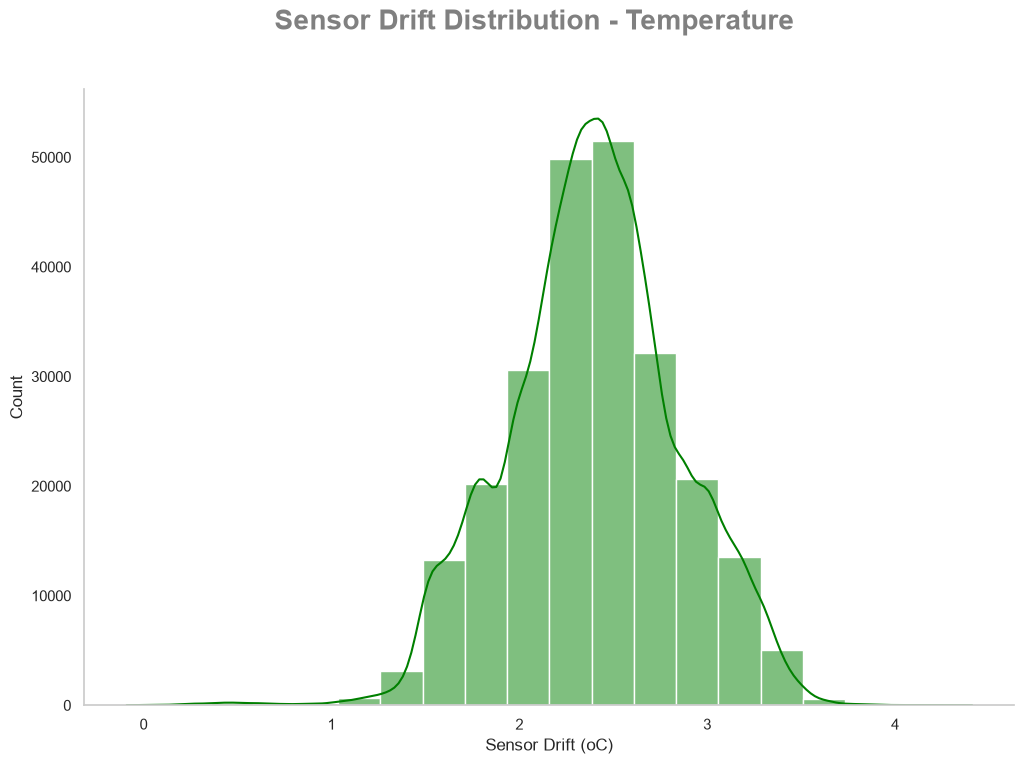

In [17]:
plot.plot_histogram(
    dfs=[tmp_sensor_drift],
    x_col='Sensor Drift (oC)',
    saved_name="Sensor Drift Between Two Sensors",
    title="Sensor Drift Distribution - Temperature",
    bins=20
)

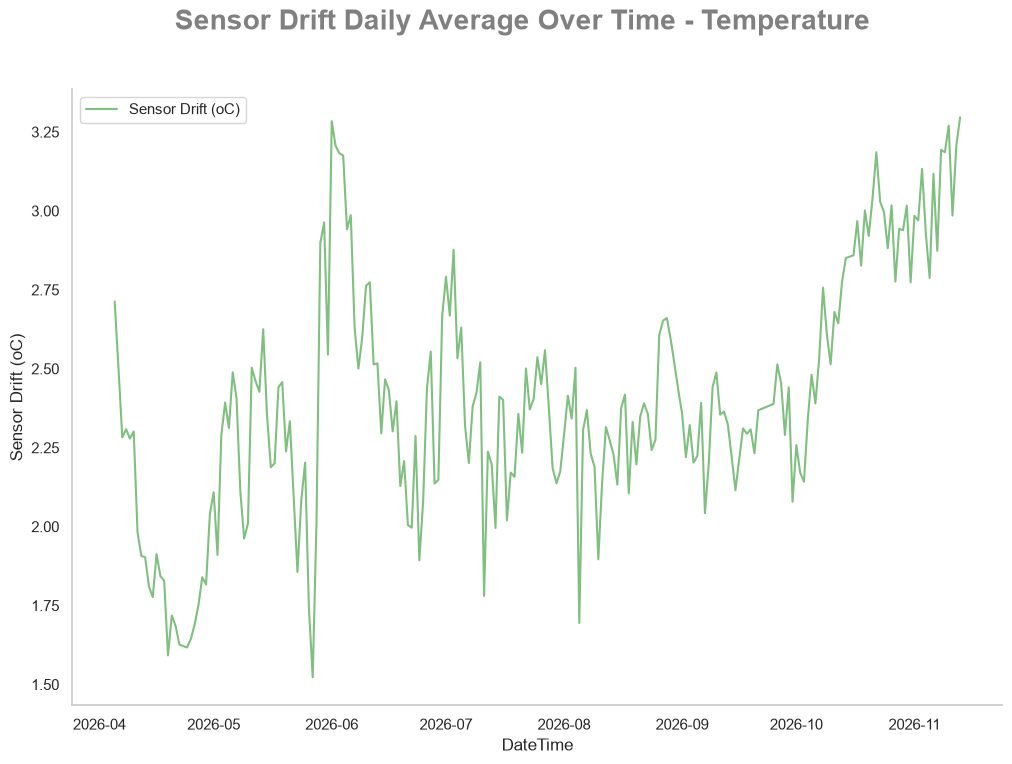

In [18]:
# How the sensor drift daily average changes over time
tmp_daily_avg_drift = tmp_sensor_drift.resample('1D').mean()


# plot the times series
plot.plot_time_series(
    dfs=[tmp_daily_avg_drift],
    x_col="DateTime",
    y_col=['Sensor Drift (oC)'],
    title="Sensor Drift Daily Average Over Time - Temperature",
    saved_name="Sensor Drift Daily Average Over Time - Temperature"
    )



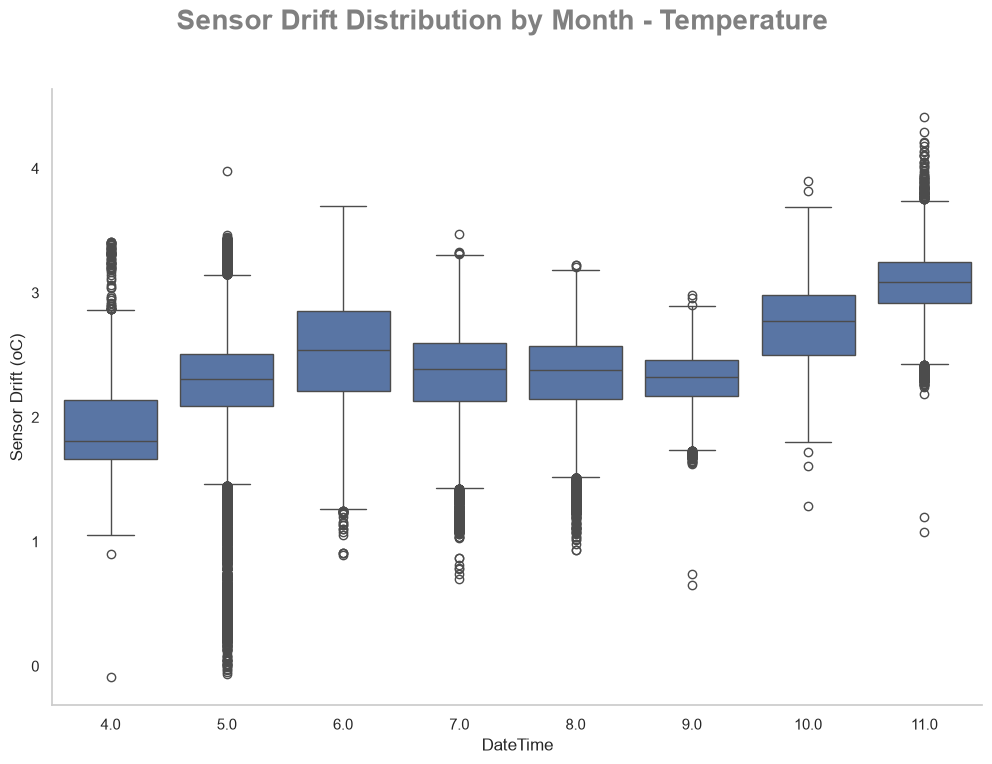

In [19]:
# lets look at how drift distribution changes over time. 
# We can do this by plotting the distribution of the sensor drift for each month. 
# This will help us understand if the sensor drift is consistent over time or if it changes significantly from month to month.

fig = plt.figure(figsize=(12, 8))

sns.boxplot(
    x=tmp_sensor_drift.index.month,
    y=tmp_sensor_drift['Sensor Drift (oC)']
);

# apply standard settings to the plot
plot.plot_cleanup(
    axes=None,
    title="Sensor Drift Distribution by Month - Temperature"
    )

# save image
plot.save_image(
    fig=fig,
    file_name="Sensor Drift Distribution by Month - Temperature"
    )

##### Notes

The temperature drift between the two sesnors typically lie between 2 and 3 degrees celcius. This is interesting as the distance between the two sensors is approximately 9/10 meters, which suggests that their environments are quite different!

                            Sensor Drift (oC)  Daily Avg Door Temp (oC)  \
Sensor Drift (oC)                    1.000000                 -0.143683   
Daily Avg Door Temp (oC)            -0.143683                  1.000000   
Daily Avg Window Temp (oC)          -0.273895                  0.990938   

                            Daily Avg Window Temp (oC)  
Sensor Drift (oC)                            -0.273895  
Daily Avg Door Temp (oC)                      0.990938  
Daily Avg Window Temp (oC)                    1.000000  


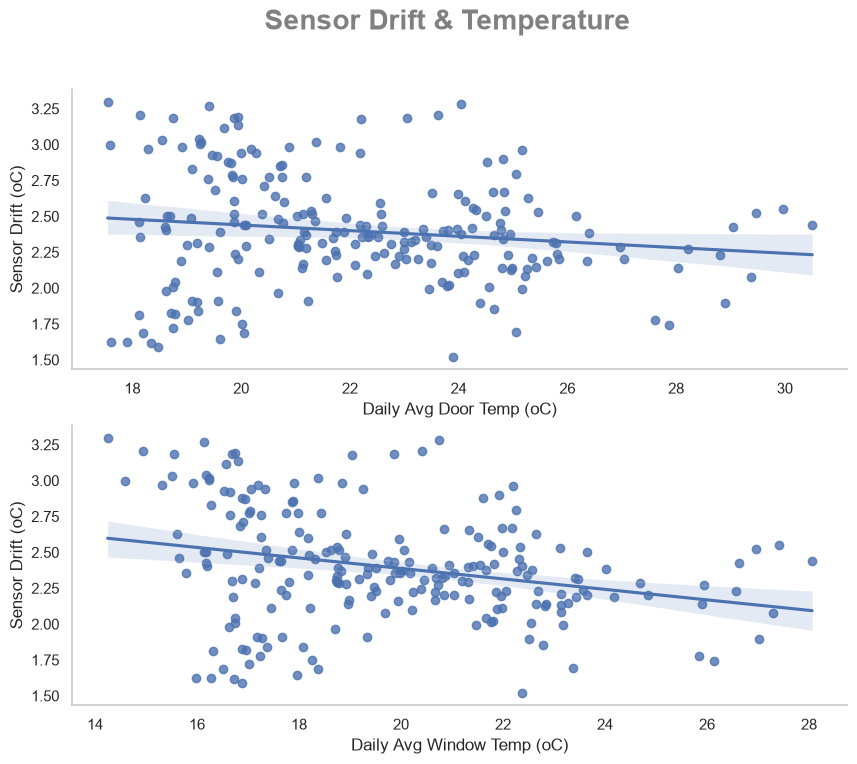

In [20]:
tmp_daily_avg_drift.rename(columns={'Temperature (oC)':'Sensor Drift (oC)'}, inplace=True)

# create daily avg features
tmp_daily_avg_drift['Daily Avg Door Temp (oC)'] = door_df['Temperature (oC)'].resample('D').mean()
tmp_daily_avg_drift['Daily Avg Window Temp (oC)'] = window_df['Temperature (oC)'].resample('D').mean()

plot.plot_relationships(
    df=tmp_daily_avg_drift,
    x_col=['Daily Avg Door Temp (oC)','Daily Avg Window Temp (oC)'],
    y_col='Sensor Drift (oC)',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

                            Sensor Drift (oC)  Daily Avg Door Temp (oC)  \
Sensor Drift (oC)                    1.000000                 -0.143683   
Daily Avg Door Temp (oC)            -0.143683                  1.000000   
Daily Avg Window Temp (oC)          -0.273895                  0.990938   
Daily Avg Door Humidity              0.366427                 -0.532369   
Daily Avg Window Humidity            0.470480                 -0.600492   

                            Daily Avg Window Temp (oC)  \
Sensor Drift (oC)                            -0.273895   
Daily Avg Door Temp (oC)                      0.990938   
Daily Avg Window Temp (oC)                    1.000000   
Daily Avg Door Humidity                      -0.565911   
Daily Avg Window Humidity                    -0.646864   

                            Daily Avg Door Humidity  Daily Avg Window Humidity  
Sensor Drift (oC)                          0.366427                   0.470480  
Daily Avg Door Temp (oC)              

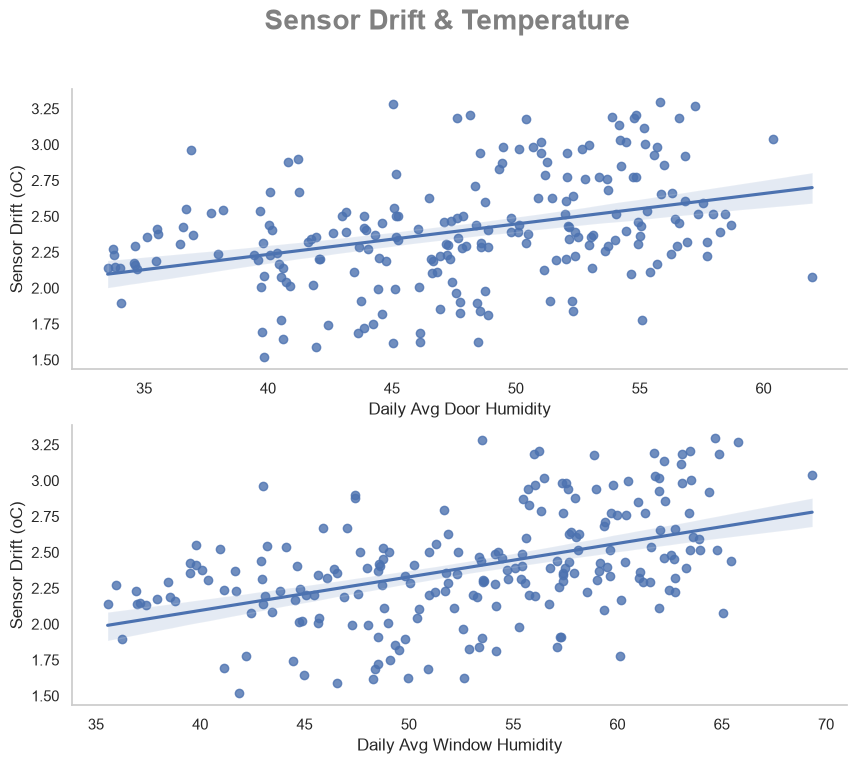

In [21]:
tmp_daily_avg_drift['Daily Avg Door Humidity'] = door_df['Humidity'].resample('D').mean()
tmp_daily_avg_drift['Daily Avg Window Humidity'] = window_df['Humidity'].resample('D').mean()

plot.plot_relationships(
    df=tmp_daily_avg_drift,
    x_col=['Daily Avg Door Humidity','Daily Avg Window Humidity'],
    y_col='Sensor Drift (oC)',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

##### **Notes**

1. The drift between 2 sensors appears to be getting worse as we draw closer to colder months - This suggests that one side of the room gets colder relative to the other side. However, more data is needed (Winter months) to determine if this is the case (a pattern should emergy where the difference remains around 2/3 degrees).
2. In addition to point one, the spikes in the daily avg sample appears to correlate with the spikes in temperature further evdidencing that one side of the room is more sensitive to temperature changes than the other. More evidence is required!
3. The counter argument to point one and two is the lack of evidence in correlation between drift and daily average temperature of each location.
4. There is a stronger relationship between Daily Avg Humidity levels and temperature drift, suggesting this factor may play a role. However, more analysis is required!
5. The positive relationship between Daily Avg Window Humidity and Sensor Drift suggests that the steady increase in humidity levels, the worse the drift get.

#### Humidity Sensor Drift

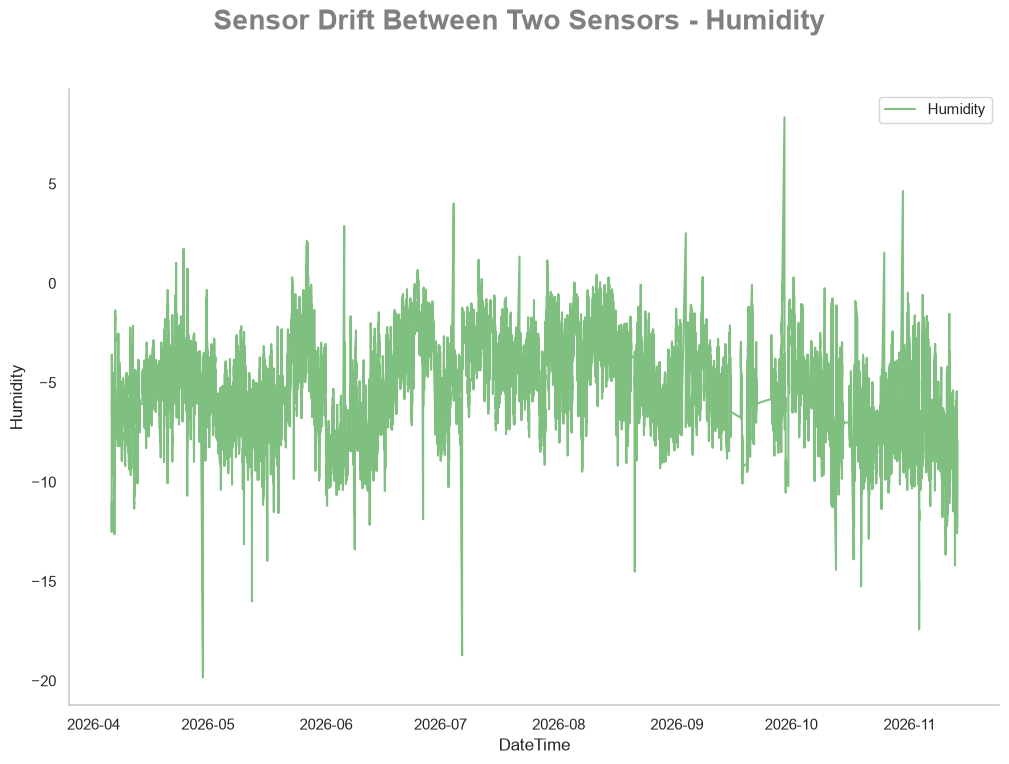

In [22]:
# How much of a difference is there between the two sensors humidity?

hum_sensor_drift = pd.DataFrame((door_df['Humidity'] - window_df['Humidity']).dropna())


plot.plot_time_series(
    dfs=[hum_sensor_drift], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors Over Time - Humidity"
    )

count    241933.000000
mean         -5.210908
std           2.098983
min         -19.828124
25%          -6.661134
50%          -5.152346
75%          -3.756836
max           8.352540
Name: Humidity, dtype: float64 

Skewness: -0.06522700975186724
Kurtosis: -0.10855537640300605


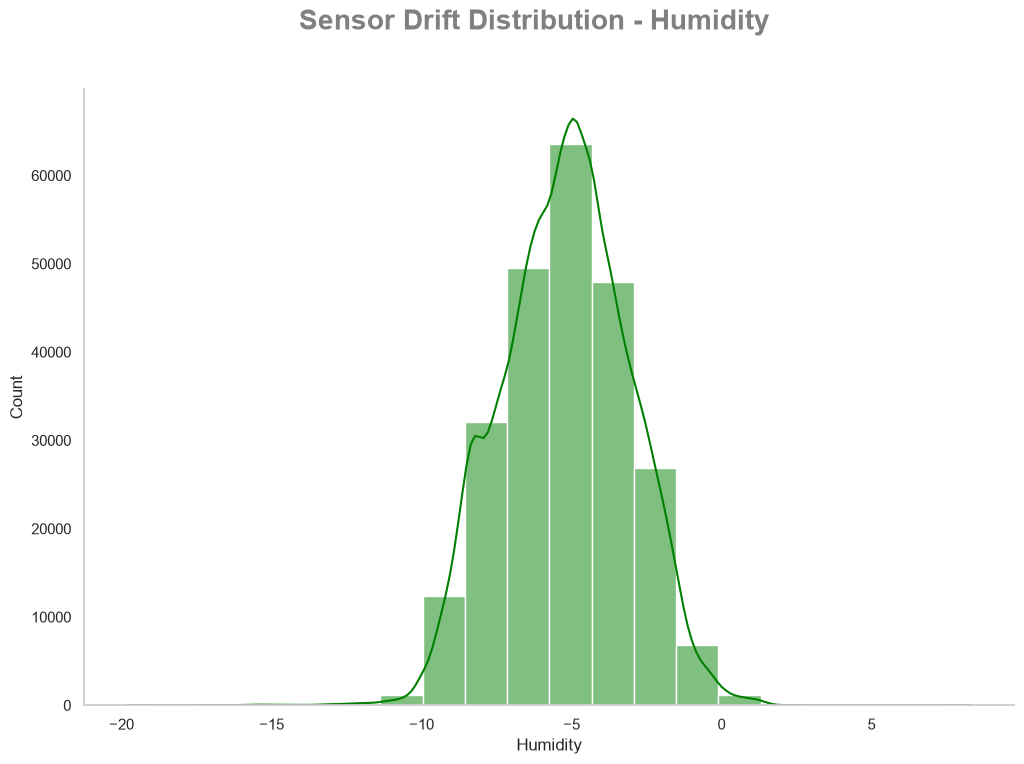

In [23]:
# show distribution
plot.plot_histogram(
    dfs=[hum_sensor_drift],
    x_col="Humidity",
    saved_name="Sensor Drift Distribution - Humidity",
    title="Sensor Drift Distribution - Humidity",
    bins=20
)

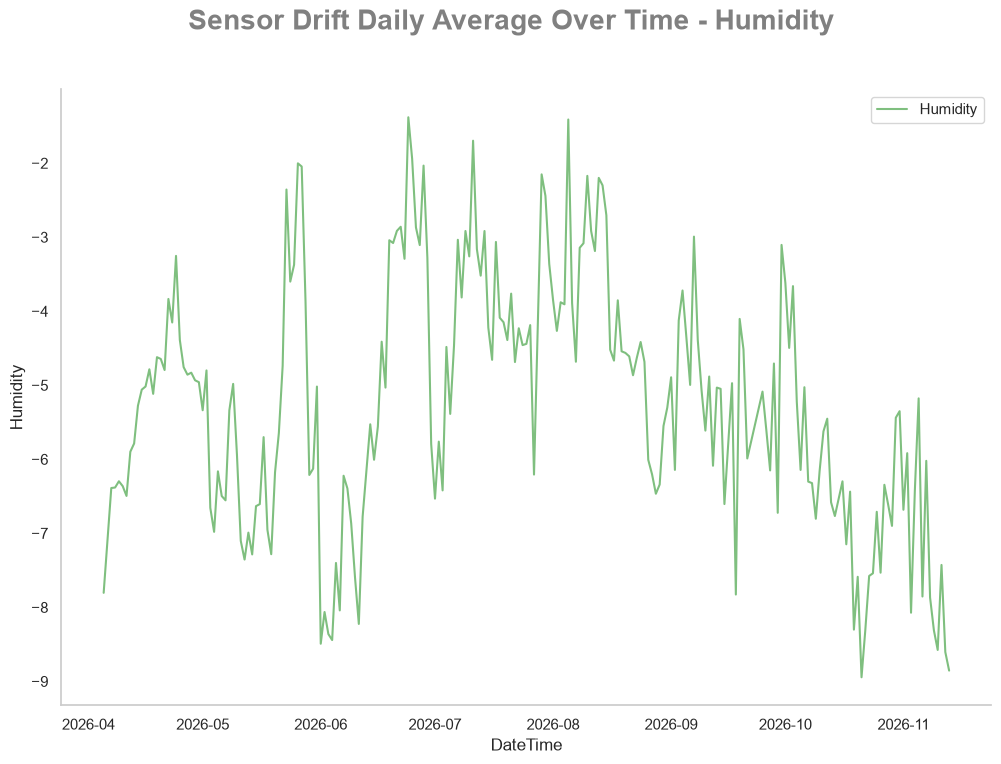

In [24]:
# review daily avg over time
hum_sensor_drift_daily_avg = hum_sensor_drift.resample('1D').mean()


# plot the times series
plot.plot_time_series(
    dfs=[hum_sensor_drift_daily_avg],
    x_col="DateTime",
    y_col=["Humidity"],
    title="Sensor Drift Daily Average Over Time - Humidity",
    saved_name="Sensor Drift Daily Average Over Time - Humidity"
    )

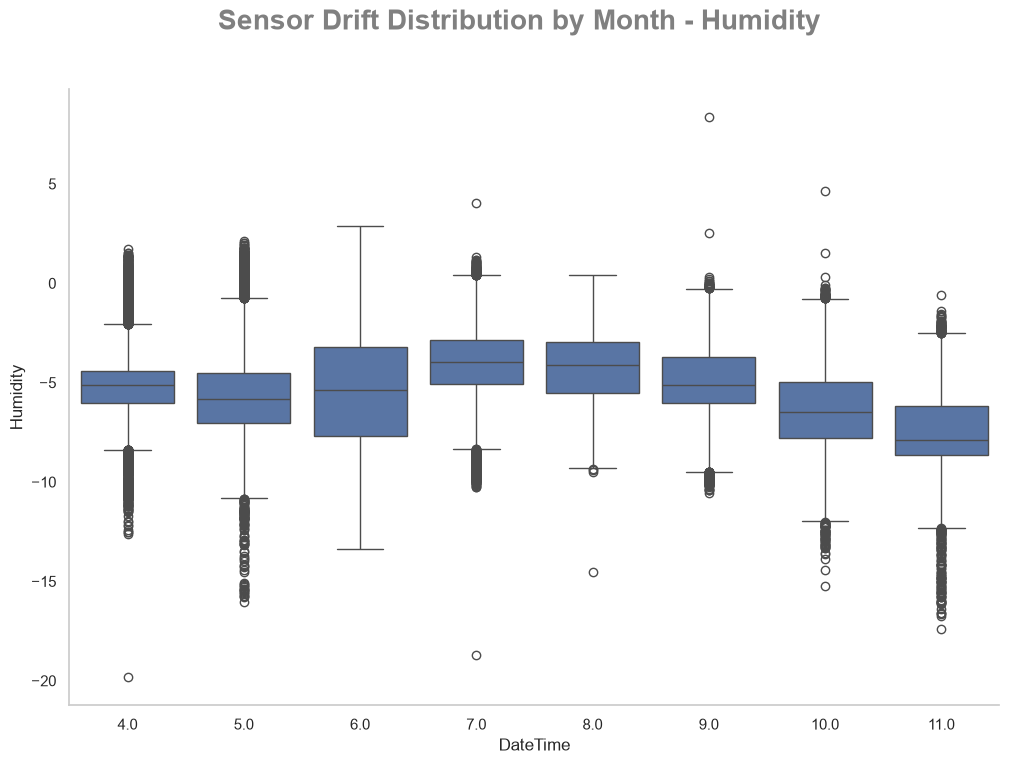

In [26]:
# lets review how the sensor drift distribution changes over time for humidity.
fig = plt.figure(figsize=(12, 8))

sns.boxplot(
    x=hum_sensor_drift.index.month,
    y=hum_sensor_drift['Humidity']
);

# apply standard settings to the plot
plot.plot_cleanup(
    axes=None,
    title="Sensor Drift Distribution by Month - Humidity"
    )

# save image
plot.save_image(
    fig=fig,
    file_name="Sensor Drift Distribution by Month - Humidity"
    )

                            Humidity Sensor Drift  Daily Avg Door Temp (oC)  \
Humidity Sensor Drift                    1.000000                  0.661656   
Daily Avg Door Temp (oC)                 0.661656                  1.000000   
Daily Avg Window Temp (oC)               0.739266                  0.990941   

                            Daily Avg Window Temp (oC)  
Humidity Sensor Drift                         0.739266  
Daily Avg Door Temp (oC)                      0.990941  
Daily Avg Window Temp (oC)                    1.000000  


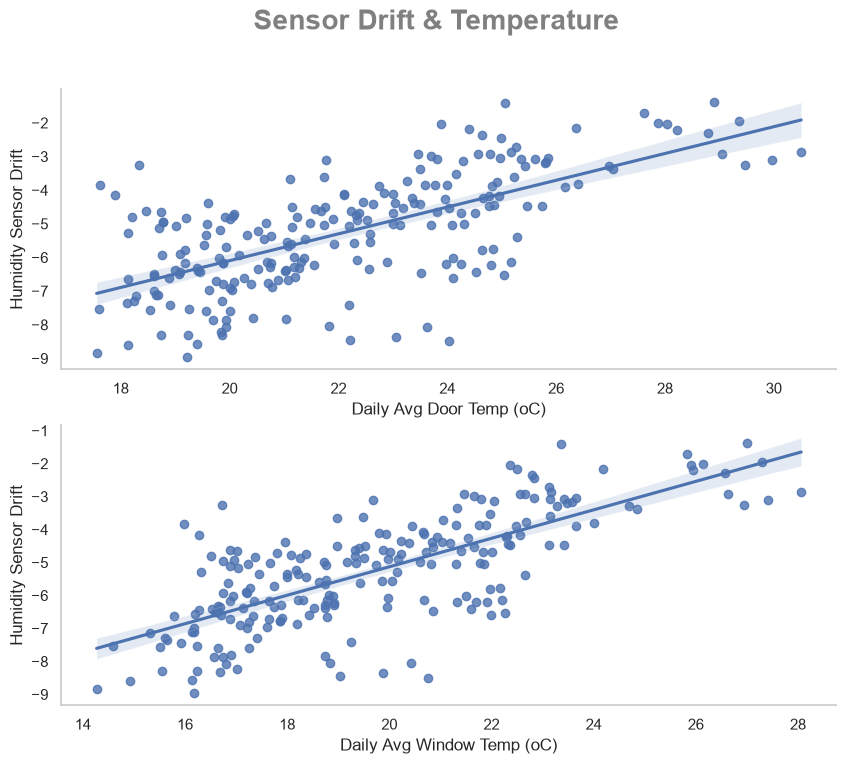

In [ ]:
# what is the relationships between the two sensors temp and humidity drift?
hum_sensor_drift.rename(columns={'Humidity':'Humidity Sensor Drift'}, inplace=True)

# create daily avg features
hum_sensor_drift['Daily Avg Door Temp (oC)'] = door_df['Temperature (oC)'].resample('D').mean()
hum_sensor_drift['Daily Avg Window Temp (oC)'] = window_df['Temperature (oC)'].resample('D').mean()

plot.plot_relationships(
    df=hum_sensor_drift,
    x_col=['Daily Avg Door Temp (oC)','Daily Avg Window Temp (oC)'],
    y_col='Humidity Sensor Drift',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

##### Notes

1. The relationships plotted suggests that in the colder months, the drift between sensors for humidity gets worse meaning humidity levels become wrose on one side of the room compared to the other.
2. The wondow is more sensitive to drift in colder temperatures, meaning humidity is ~5% to 9% worse that the door sensor.
3. The change in humidity drift is more sensitive compared to temperature.

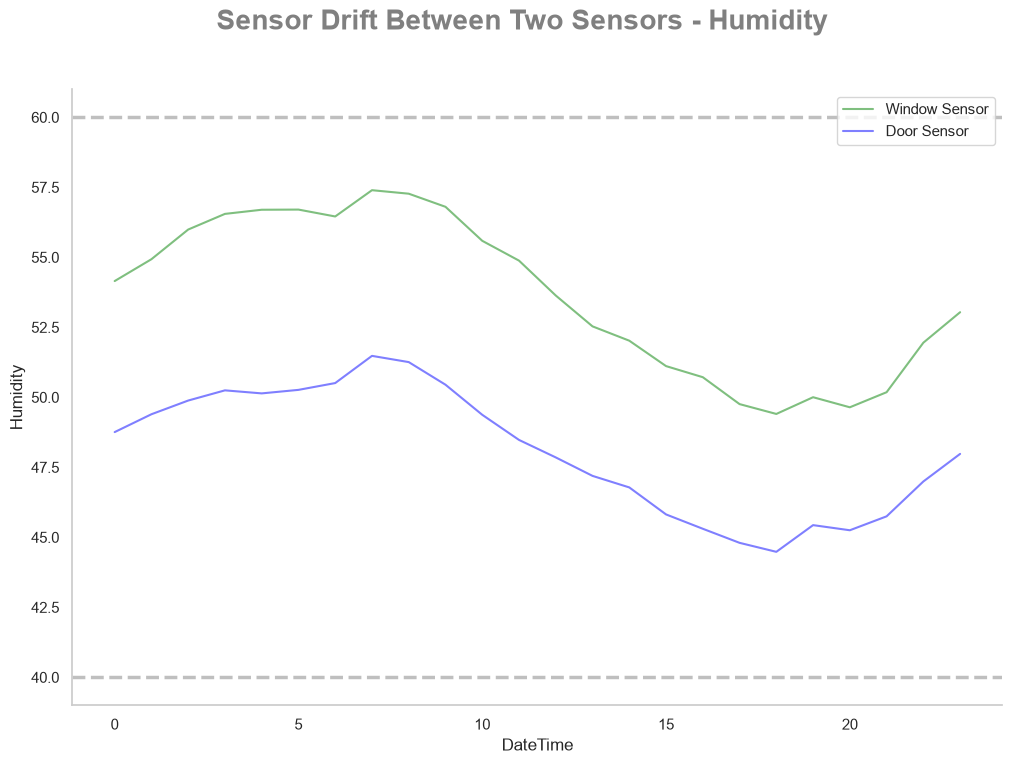

In [ ]:
# lets do the same except this time focus on time of the day

hum_hourly_win = window_df.groupby(window_df.index.hour)['Humidity'].median().reset_index()
hum_hourly_door = door_df.groupby(door_df.index.hour)['Humidity'].median().reset_index()

# plot the line
plot.plot_time_series(
    dfs=[hum_hourly_win,hum_hourly_door], 
    x_col='DateTime', 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors Over Time - Humidity",
    add_hlines=True
    )

#### Notes

1. Humidity levels typically peak around 7am/8am.
2. The lowest levels typicall lie between 4pm and 6pm then augements as it goes into the night.
3. The negative of taking the entire sample is that it consider warmer months where humidity levels were lower. Next step is to filter the data from Oct to date and compare the differences!

To tackle the humidity problem, it seems that the worse levels happens during the night/early morning. It would be interesting to see the data as we get into the winter!

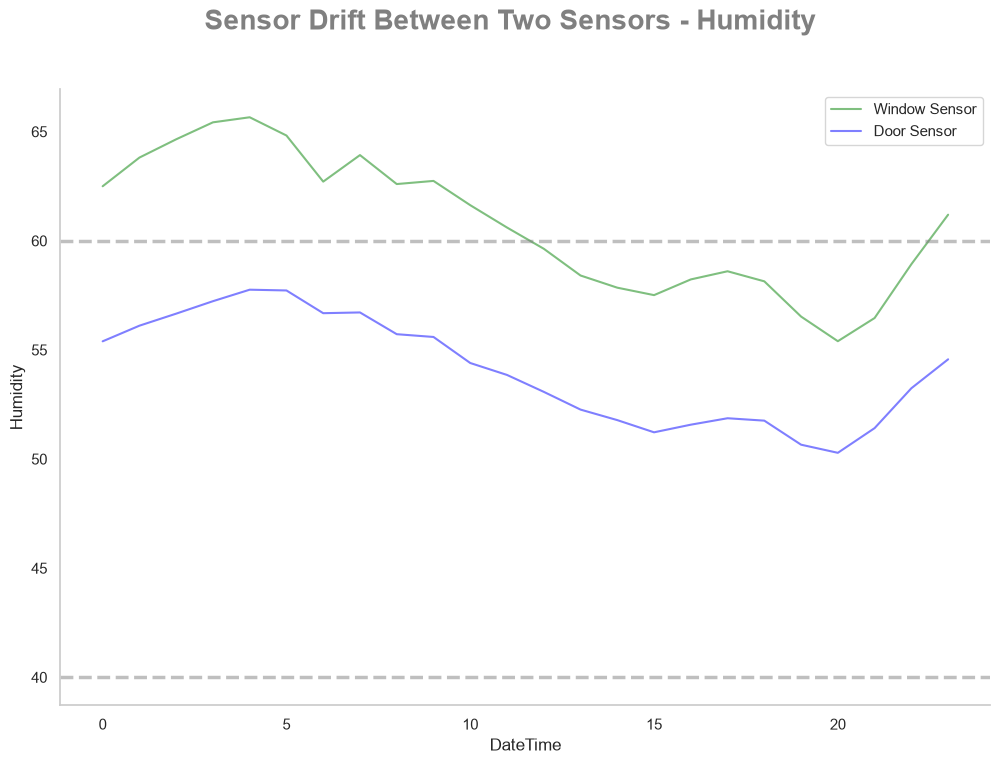

In [ ]:
# lets do the same except this time focus on time of the day
win_oct_to_date_mask = (window_df.index >= '2026-10-01') 
door_oct_to_date_mask = (door_df.index >= '2026-10-01') 

cold_hum_hourly_win = (
    window_df
    .loc[win_oct_to_date_mask]
    .groupby(window_df.loc[win_oct_to_date_mask].index.hour)['Humidity']
    .median()
    .reset_index()
    )

cold_hum_hourly_door = (
    door_df
    .loc[door_oct_to_date_mask]
    .groupby(door_df.loc[door_oct_to_date_mask].index.hour)['Humidity']
    .median()
    .reset_index()
    )

# plot the line
plot.plot_time_series(
    dfs=[cold_hum_hourly_win,cold_hum_hourly_door], 
    x_col='DateTime', 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors From Oct 2026 to Date - Humidity",
    add_hlines=True
    )


##### Notes

This is a classic case of data drift where newer data distribution has shifted from older data -> the influence of changing seasons! however, the overall pattern remains the same where we observe an S-curve over time, but peaks earlier than the overall dataset (around 4am rather than 5/6am).

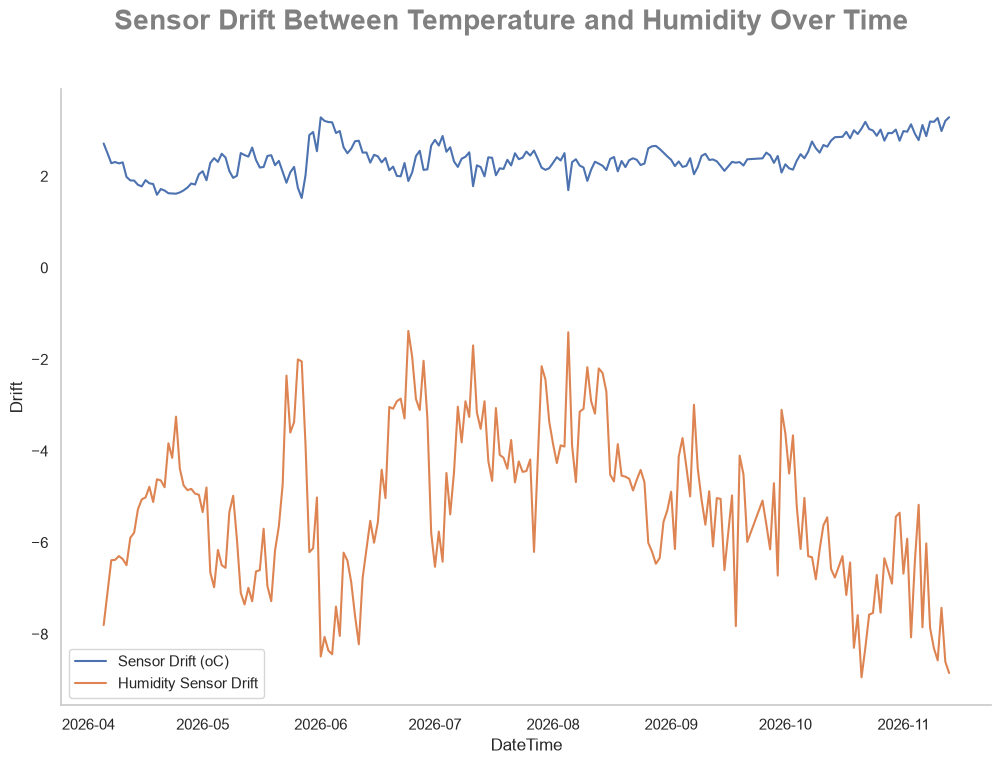

In [ ]:
fig = plt.figure(figsize=(12,8))

hum_and_tmp_drift = pd.concat(
    [
        tmp_daily_avg_drift[['Sensor Drift (oC)']], 
        hum_sensor_drift[['Humidity Sensor Drift']]
        ], 
        axis=1
)

for feature in ['Sensor Drift (oC)','Humidity Sensor Drift']:
    sns.lineplot(
        data=hum_and_tmp_drift,
        x=hum_and_tmp_drift.index,
        y=feature,
        label=feature
    )

plt.legend()

# clean up for standrad settings
plot.plot_cleanup(
    title="Sensor Drift Between Temperature and Humidity Over Time",
    xlabel="DateTime",
    ylabel="Drift"
)

# save the image
plot.save_image(
    file_name="Sensor Drift Between Temperature and Humidity Over Time",
    fig=fig
)

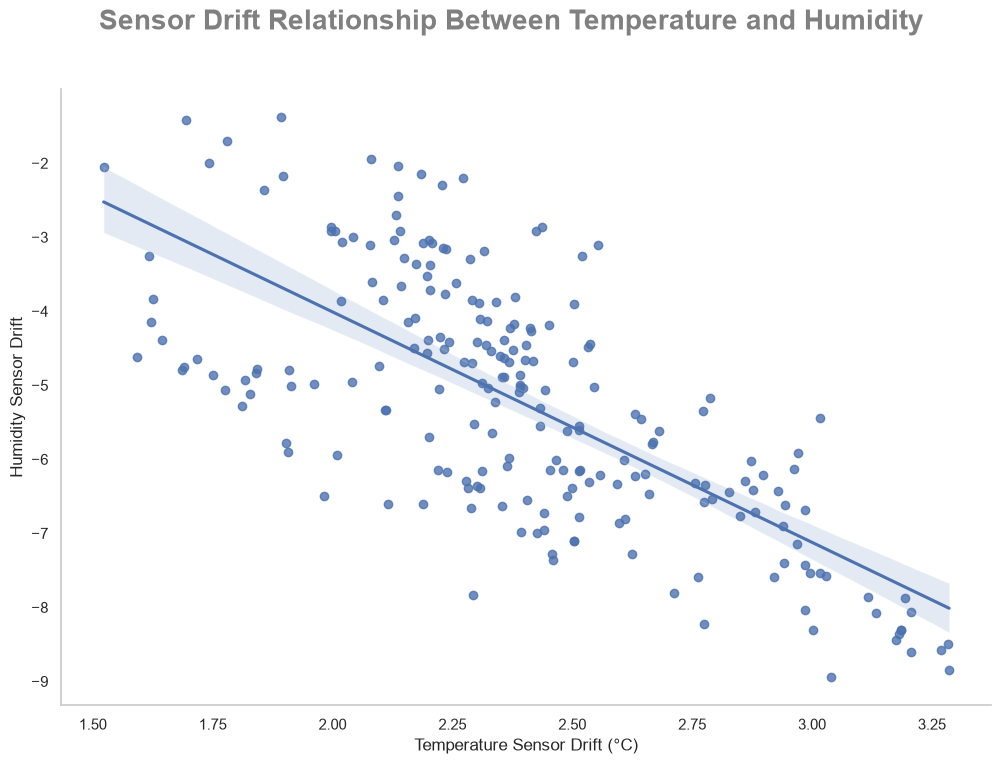

In [ ]:
fig = plt.figure(figsize=(12,8))


sns.regplot(
    data=hum_and_tmp_drift.dropna(),
    x='Sensor Drift (oC)',
    y='Humidity Sensor Drift',
    label='Humidity Sensor Drift'
)

plot.plot_cleanup(
    title="Sensor Drift Relationship Between Temperature and Humidity",
    xlabel="Temperature Sensor Drift (°C)",
    ylabel="Humidity Sensor Drift"
)

# save the image
plot.save_image(
    file_name="Sensor Drift Relationship Between Temperature and Humidity",
    fig=fig
)